# Assignment 11 - Probing BERT's Encoder Layers

**Name:** Tanu Meena  
**Roll number:** U23AI076

We sample 50,000 examples for each SentEval task, split them 90:10, and
train 12 independent logistic regression probes per task. BERT is frozen.
This follows the earlier labs' fixed seed, stratification, saved predictions,
metrics, and plots. Each classifier receives sentence representations only.

`google/bert_uncased_L-12_H-128_A-2` is a pretrained compact BERT with
**12 actual encoder layers**, hidden size 128 and two attention heads.
A six-layer DistilBERT would not meet the requested 12-probe requirement.

The assignment cites https://arxiv.org/abs/1803.05449, the SentEval toolkit
paper. The dataset README identifies https://arxiv.org/abs/1805.01070 as the
paper describing these probing tasks. Neither supplies exact expected scores
for this compact BERT and our newly sampled splits.

In [1]:
import hashlib
import json
import os
import random
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoModel, AutoTokenizer

LAB_DIR = (Path(__file__).resolve().parent if '__file__' in globals() else
           Path.cwd() if (Path.cwd() / 'Assignment11_BERT_Layer_Probing.py').exists()
           else Path.cwd() / 'Lab11')
OUT = LAB_DIR / 'assignment11_artifacts'
for sub in ['raw', 'data', 'features', 'models', 'plots']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
SEED = 42
SAMPLES = 50_000
TRAIN_SIZE = 45_000
MODEL_ID = 'google/bert_uncased_L-12_H-128_A-2'
REVISION = '769ccb240a0acd026d94f84a96e8a754e4b8eff1'
TASKS = ['sentence_length', 'bigram_shift', 'subj_number']
BATCH_SIZE = int(os.getenv('LAB11_BATCH_SIZE', '128'))
MAX_LENGTH = 128
torch.set_num_threads(int(os.getenv('LAB_THREADS', '4')))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

## 1. Download, audit, and sample the data

Each row contains an original split, a label, and a sentence. The lab asks for
a new 90:10 split, so we pool the original partitions and preserve their IDs
for provenance. Repeated sentences are removed, and sentences with conflicting
labels are excluded before sampling, preventing exact-text leakage.

The binary tasks have 25,000 examples per class. Sentence length has six
classes, and 50,000 is not divisible by six. Four classes therefore contain
8,333 examples and two contain 8,334. The training split has exactly 7,500
per class; the test split has 833 or 834. No examples are duplicated to balance.

Sentence-length labels use the original space-delimited SentEval tokens,
including punctuation, rather than the number of BERT WordPieces:

| Label | Sentence length |
| --- | --- |
| 0 | 5-8 tokens |
| 1 | 9-12 tokens |
| 2 | 13-16 tokens |
| 3 | 17-20 tokens |
| 4 | 21-25 tokens |
| 5 | 26-28 tokens |

Bigram-shift labels are `I` for an inverted adjacent pair and `O` for the
original order. Subject-number labels are `NN` (singular) and `NNS` (plural).

In [2]:
source_meta = {}
datasets = {}
class_counts = []
for task in TASKS:
    raw = OUT / 'raw' / f'{task}.txt'
    url = f'https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/{task}.txt'
    if not raw.exists():
        response = requests.get(url, timeout=(20, 120))
        response.raise_for_status()
        raw.write_bytes(response.content)
    records = []
    for line_id, line in enumerate(raw.read_text(encoding='utf-8').splitlines(), 1):
        fields = line.split('\t')
        if len(fields) < 3 or fields[0] not in {'tr', 'va', 'te'}:
            raise ValueError(f'Malformed {task} row {line_id}')
        records.append({'original_split': fields[0], 'label': fields[1],
                        'sentence': fields[-1], 'row_id': line_id})
    frame = pd.DataFrame(records)
    conflicts = frame.groupby('sentence').label.nunique()
    conflict_texts = set(conflicts[conflicts > 1].index)
    clean = frame.loc[~frame.sentence.isin(conflict_texts)].drop_duplicates('sentence')
    labels = sorted(clean.label.unique())
    train_parts, test_parts = [], []
    rng = np.random.default_rng(SEED)
    for i, label in enumerate(labels):
        total = SAMPLES // len(labels) + int(i < SAMPLES % len(labels))
        train_n = TRAIN_SIZE // len(labels)
        group = clean.loc[clean.label == label]
        if len(group) < total:
            raise ValueError(f'{task}/{label}: insufficient unique sentences')
        selected = group.iloc[rng.choice(len(group), total, replace=False)]
        train_parts.append(selected.iloc[:train_n])
        test_parts.append(selected.iloc[train_n:])
    train = pd.concat(train_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    test = pd.concat(test_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    assert len(train) == 45_000 and len(test) == 5_000
    assert not set(train.sentence) & set(test.sentence)
    for split, data in [('train', train), ('test', test)]:
        data.to_csv(OUT / 'data' / f'{task}_{split}.csv', index=False)
        for label in labels:
            class_counts.append({'task': task, 'split': split, 'label': label,
                                 'samples': int((data.label == label).sum())})
    datasets[task] = (train, test, labels)
    source_meta[task] = {'url': url, 'raw_sha256': sha256(raw), 'raw_rows': len(frame),
                         'conflicting_sentences': len(conflict_texts),
                         'unique_consistent_rows': len(clean),
                         'split_sha256': {s: sha256(OUT / 'data' / f'{task}_{s}.csv')
                                          for s in ['train', 'test']}}
counts = pd.DataFrame(class_counts)
counts.to_csv(OUT / 'class_balance.csv', index=False)
save_json(OUT / 'data_manifest.json', {'seed': SEED, 'sources': source_meta})
display(counts)

,task,split,label,samples
0,sentence_length,train,0,7500
1,sentence_length,train,1,7500
2,sentence_length,train,2,7500
3,sentence_length,train,3,7500
4,sentence_length,train,4,7500
5,sentence_length,train,5,7500
6,sentence_length,test,0,834
7,sentence_length,test,1,834
8,sentence_length,test,2,833
9,sentence_length,test,3,833


## 2. Extract the sentence representation at every encoder layer

For layer l, we average the contextual token vectors over actual content
tokens, excluding padding, `[CLS]`, and `[SEP]`. This avoids giving the probe
padding or explicit length metadata. Mean pooling can still preserve length
indirectly through the contextual states. `hidden_states[0]` is the embedding
output and is excluded; layers 1 through 12 are probed.

The model runs in evaluation mode under inference mode, with all parameters
frozen. Training and test representations use the same encoder. Token lengths
are audited: a sentence above 128 pieces raises an error instead of silently
losing information. Disk arrays keep all 12 layers without exhausting RAM.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
encoder = AutoModel.from_pretrained(MODEL_ID, revision=REVISION).to(DEVICE)
encoder.eval()
encoder.requires_grad_(False)
assert encoder.config.num_hidden_layers == 12
HIDDEN = encoder.config.hidden_size
print('Encoder:', MODEL_ID, 'layers:', encoder.config.num_hidden_layers,
      'hidden:', HIDDEN, 'parameters:', sum(p.numel() for p in encoder.parameters()))
feature_paths = {}
for task, (train, test, labels) in datasets.items():
    sentences = pd.concat([train, test]).sentence.tolist()
    feature_file = OUT / 'features' / f'{task}.npy'
    marker = OUT / 'features' / f'{task}.json'
    settings = {'model': MODEL_ID, 'revision': REVISION,
                'splits': source_meta[task]['split_sha256'], 'pooling': 'content_token_mean',
                'shape': [12, SAMPLES, HIDDEN], 'max_length': MAX_LENGTH}
    previous = json.loads(marker.read_text()) if marker.exists() else {}
    if not (previous.get('settings') == settings and feature_file.exists()
            and previous.get('sha256') == sha256(feature_file)):
        encoded = tokenizer(sentences, add_special_tokens=True,
                            return_special_tokens_mask=True, truncation=False)
        lengths = np.array([len(x) for x in encoded['input_ids']])
        if lengths.max() > MAX_LENGTH:
            raise ValueError(f'{task} has {lengths.max()} pieces; increase MAX_LENGTH')
        features = np.lib.format.open_memmap(feature_file, mode='w+', dtype='float32',
                                             shape=(12, SAMPLES, HIDDEN))
        order = np.argsort(lengths, kind='stable')
        started = time.perf_counter()
        with torch.inference_mode():
            for start in range(0, SAMPLES, BATCH_SIZE):
                indices = order[start:start+BATCH_SIZE]
                rows = [{key: encoded[key][int(i)] for key in encoded} for i in indices]
                batch = tokenizer.pad(rows, padding=True, return_tensors='pt')
                special = batch.pop('special_tokens_mask').to(DEVICE)
                batch = {key: value.to(DEVICE) for key, value in batch.items()}
                mask = (batch['attention_mask'] * (1 - special)).unsqueeze(-1)
                states = encoder(**batch, output_hidden_states=True).hidden_states
                assert len(states) == 13
                denominator = mask.sum(1).clamp(min=1)
                for layer in range(12):
                    pooled = (states[layer+1] * mask).sum(1) / denominator
                    features[layer, indices, :] = pooled.cpu().numpy()
                if start % (BATCH_SIZE * 40) == 0:
                    print(f'{task}: {start}/{SAMPLES}, {time.perf_counter()-started:.1f}s', flush=True)
        features.flush()
        del features
        save_json(marker, {'settings': settings, 'sha256': sha256(feature_file),
                           'seconds': time.perf_counter()-started,
                           'max_tokens': int(lengths.max()), 'truncated': 0})
    feature_paths[task] = feature_file
    print(task, 'representations ready', flush=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-12_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoder: google/bert_uncased_L-12_H-128_A-2 layers: 12 hidden: 128 parameters: 6368640
sentence_length representations ready
bigram_shift representations ready
subj_number representations ready


## 3. Fit 36 independent logistic regression classifiers

Each probe is `StandardScaler -> LogisticRegression` with L2 regularization,
C=1, LBFGS, and up to 1,000 iterations. The scaler is fitted only on training
features. Softmax handles the six length classes, while sigmoid handles the
binary tasks. The encoder receives no gradient. C and pooling are fixed
before observing the test set; the test-layer ranking is descriptive.

We report accuracy and macro-F1. Chance accuracy is approximately 1/6 for
sentence length and 1/2 for the binary tasks. High probe accuracy means that
a linear classifier can recover information, not that BERT explicitly uses
it in every downstream prediction.

In [4]:
results = []
for task, (train, test, labels) in datasets.items():
    features = np.load(feature_paths[task], mmap_mode='r')
    predictions = test[['row_id', 'sentence', 'label']].rename(columns={'label': 'gold'}).copy()
    for layer in range(12):
        started = time.perf_counter()
        probe = make_pipeline(StandardScaler(), LogisticRegression(
            C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED))
        probe.fit(features[layer, :TRAIN_SIZE], train.label)
        prediction = probe.predict(features[layer, TRAIN_SIZE:])
        prediction = np.asarray(prediction).astype(str)
        assert probe[-1].n_iter_.max() < 1000, 'Probe did not converge'
        predictions[f'layer_{layer+1}'] = prediction
        row = {'task': task, 'layer': layer+1,
               'test_accuracy': accuracy_score(test.label, prediction),
               'test_macro_f1': f1_score(test.label, prediction, average='macro'),
               'iterations': int(probe[-1].n_iter_.max()),
               'training_seconds': time.perf_counter()-started}
        results.append(row)
        joblib.dump(probe, OUT / 'models' / f'{task}_layer_{layer+1:02d}.joblib')
        pd.DataFrame(confusion_matrix(test.label, prediction, labels=labels),
                     index=labels, columns=labels).to_csv(OUT / f'{task}_layer_{layer+1:02d}_confusion.csv')
        save_json(OUT / f'{task}_layer_{layer+1:02d}_metrics.json',
                  classification_report(test.label, prediction, labels=labels, output_dict=True))
        print(task, 'layer', layer+1, 'accuracy', round(row['test_accuracy'], 4), flush=True)
    predictions.to_csv(OUT / f'{task}_test_predictions.csv', index=False)
    del features
results = pd.DataFrame(results)
assert len(results) == 36
results.to_csv(OUT / 'layer_probe_results.csv', index=False)
display(results.pivot(index='layer', columns='task', values='test_accuracy').round(4))

sentence_length layer 1 accuracy 0.9694
sentence_length layer 2 accuracy 0.9668
sentence_length layer 3 accuracy 0.963
sentence_length layer 4 accuracy 0.9616
sentence_length layer 5 accuracy 0.967
sentence_length layer 6 accuracy 0.9626
sentence_length layer 7 accuracy 0.9466
sentence_length layer 8 accuracy 0.9458
sentence_length layer 9 accuracy 0.931
sentence_length layer 10 accuracy 0.9182
sentence_length layer 11 accuracy 0.904
sentence_length layer 12 accuracy 0.8906
bigram_shift layer 1 accuracy 0.5074
bigram_shift layer 2 accuracy 0.5054
bigram_shift layer 3 accuracy 0.5022
bigram_shift layer 4 accuracy 0.506
bigram_shift layer 5 accuracy 0.517
bigram_shift layer 6 accuracy 0.6616
bigram_shift layer 7 accuracy 0.7038
bigram_shift layer 8 accuracy 0.7838
bigram_shift layer 9 accuracy 0.7906
bigram_shift layer 10 accuracy 0.7848
bigram_shift layer 11 accuracy 0.7828
bigram_shift layer 12 accuracy 0.7772
subj_number layer 1 accuracy 0.8102
subj_number layer 2 accuracy 0.8136
subj

task,bigram_shift,sentence_length,subj_number
layer,,,
1,0.5074,0.9694,0.8102
2,0.5054,0.9668,0.8136
3,0.5022,0.9630,0.8096
4,0.5060,0.9616,0.8126
5,0.5170,0.9670,0.8136
6,0.6616,0.9626,0.8184
7,0.7038,0.9466,0.8124
8,0.7838,0.9458,0.8152
9,0.7906,0.9310,0.8172


## 4. Compare layers and explain the measured results

Sentence length concerns surface information. Bigram shift asks whether two
adjacent words have been swapped, so order and local syntax matter. Subject
number asks whether the main-clause subject is singular (NN) or plural (NNS),
requiring morphological and syntactic cues. These tasks can peak at different
layers. We do not assume a monotonic improvement with depth.

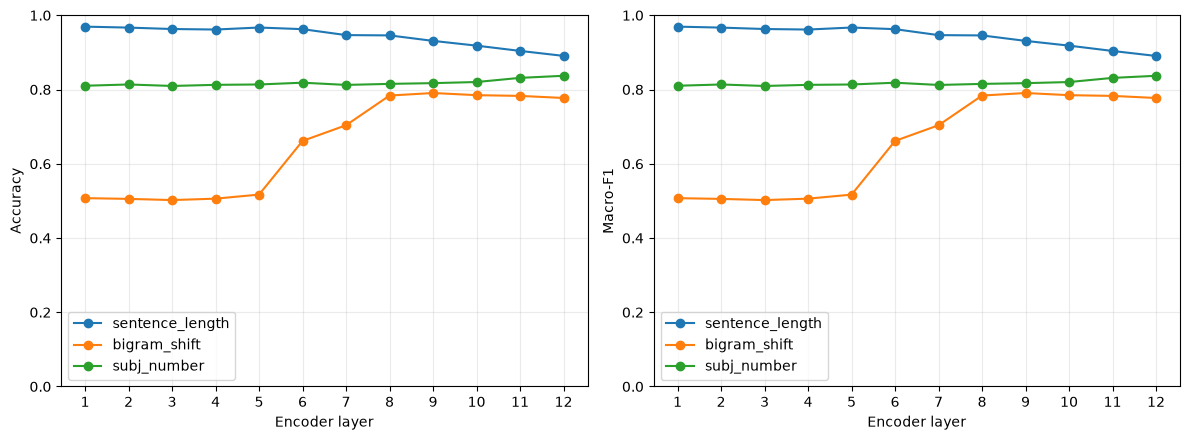

# Assignment 11 - BERT Layer Probing

Tanu Meena, U23AI076

Pretrained encoder: `google/bert_uncased_L-12_H-128_A-2` at `769ccb240a0acd026d94f84a96e8a754e4b8eff1`. Twelve encoder layers,
hidden size 128; frozen content-token mean representations.

All three tasks use 50,000 unique sentences, 45,000 training and 5,000 test.
Binary classes are exactly balanced. Six-class counts differ by at most one.
Scaler fitting and classifier learning use only training data.

| Task | Layer | Test accuracy | Test macro-F1 |
| --- | ---: | ---: | ---: |
| sentence_length | 1 | 0.9694 | 0.9694 |
| sentence_length | 2 | 0.9668 | 0.9668 |
| sentence_length | 3 | 0.9630 | 0.9630 |
| sentence_length | 4 | 0.9616 | 0.9616 |
| sentence_length | 5 | 0.9670 | 0.9670 |
| sentence_length | 6 | 0.9626 | 0.9626 |
| sentence_length | 7 | 0.9466 | 0.9465 |
| sentence_length | 8 | 0.9458 | 0.9457 |
| sentence_length | 9 | 0.9310 | 0.9310 |
| sentence_length | 10 | 0.9182 | 0.9182 |
| sentence_length | 11 | 0.9040 | 0.9039 |
| sentence_length | 12 | 0.8906 | 0.8904 |
| bigram_shift | 1 | 0.5074 | 0.5074 |
| bigram_shift | 2 | 0.5054 | 0.5054 |
| bigram_shift | 3 | 0.5022 | 0.5022 |
| bigram_shift | 4 | 0.5060 | 0.5060 |
| bigram_shift | 5 | 0.5170 | 0.5169 |
| bigram_shift | 6 | 0.6616 | 0.6616 |
| bigram_shift | 7 | 0.7038 | 0.7038 |
| bigram_shift | 8 | 0.7838 | 0.7838 |
| bigram_shift | 9 | 0.7906 | 0.7906 |
| bigram_shift | 10 | 0.7848 | 0.7848 |
| bigram_shift | 11 | 0.7828 | 0.7828 |
| bigram_shift | 12 | 0.7772 | 0.7772 |
| subj_number | 1 | 0.8102 | 0.8102 |
| subj_number | 2 | 0.8136 | 0.8136 |
| subj_number | 3 | 0.8096 | 0.8096 |
| subj_number | 4 | 0.8126 | 0.8126 |
| subj_number | 5 | 0.8136 | 0.8135 |
| subj_number | 6 | 0.8184 | 0.8183 |
| subj_number | 7 | 0.8124 | 0.8123 |
| subj_number | 8 | 0.8152 | 0.8151 |
| subj_number | 9 | 0.8172 | 0.8171 |
| subj_number | 10 | 0.8202 | 0.8201 |
| subj_number | 11 | 0.8314 | 0.8313 |
| subj_number | 12 | 0.8370 | 0.8370 |

## Observations

sentence_length: the highest observed test accuracy is 0.9694 at layer 1. Layer 1 scores 0.9694, and layer 12 scores 0.8906. The final-minus-first difference is -0.0788. This is a comparison of fixed probes, not test-based hyperparameter tuning.

bigram_shift: the highest observed test accuracy is 0.7906 at layer 9. Layer 1 scores 0.5074, and layer 12 scores 0.7772. The final-minus-first difference is +0.2698. This is a comparison of fixed probes, not test-based hyperparameter tuning.

subj_number: the highest observed test accuracy is 0.8370 at layer 12. Layer 1 scores 0.8102, and layer 12 scores 0.8370. The final-minus-first difference is +0.0268. This is a comparison of fixed probes, not test-based hyperparameter tuning.

A linear probe measures recoverability of a property. Scores alone do not
establish that a particular layer performs grammatical reasoning. The compact
BERT, chosen pooling, new sampled splits, and one seed limit generalization.
Sentence-length chance is 0.1667; binary-task chance is 0.5000.

## References

- Dataset descriptions: https://github.com/facebookresearch/SentEval/tree/main/data/probing
- Assignment reference (toolkit): https://arxiv.org/abs/1803.05449
- Probing-task paper identified by the dataset: https://arxiv.org/abs/1805.01070
- Compact BERT: https://huggingface.co/google/bert_uncased_L-12_H-128_A-2


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for task in TASKS:
    group = results.loc[results.task == task]
    axes[0].plot(group.layer, group.test_accuracy, marker='o', label=task)
    axes[1].plot(group.layer, group.test_macro_f1, marker='o', label=task)
for ax, metric in zip(axes, ['Accuracy', 'Macro-F1']):
    ax.set(xlabel='Encoder layer', ylabel=metric, xticks=range(1, 13), ylim=(0, 1))
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'plots' / 'layer_comparison.png', dpi=180)
display(fig)
plt.close(fig)
lines = ['# Assignment 11 - BERT Layer Probing', '', 'Tanu Meena, U23AI076', '',
         f'Pretrained encoder: `{MODEL_ID}` at `{REVISION}`. Twelve encoder layers,',
         'hidden size 128; frozen content-token mean representations.', '',
         'All three tasks use 50,000 unique sentences, 45,000 training and 5,000 test.',
         'Binary classes are exactly balanced. Six-class counts differ by at most one.',
         'Scaler fitting and classifier learning use only training data.', '',
         '| Task | Layer | Test accuracy | Test macro-F1 |', '| --- | ---: | ---: | ---: |']
for row in results.itertuples(index=False):
    lines.append(f'| {row.task} | {row.layer} | {row.test_accuracy:.4f} | {row.test_macro_f1:.4f} |')
lines.extend(['', '## Observations', ''])
for task in TASKS:
    group = results.loc[results.task == task]
    best = group.loc[group.test_accuracy.idxmax()]
    first = group.iloc[0]
    last = group.iloc[-1]
    lines.append(f'{task}: the highest observed test accuracy is {best.test_accuracy:.4f} '
                 f'at layer {int(best.layer)}. Layer 1 scores {first.test_accuracy:.4f}, '
                 f'and layer 12 scores {last.test_accuracy:.4f}. The final-minus-first '
                 f'difference is {last.test_accuracy-first.test_accuracy:+.4f}. '
                 'This is a comparison of fixed probes, not test-based hyperparameter tuning.')
    lines.append('')
lines.extend(['A linear probe measures recoverability of a property. Scores alone do not',
              'establish that a particular layer performs grammatical reasoning. The compact',
              'BERT, chosen pooling, new sampled splits, and one seed limit generalization.',
              'Sentence-length chance is 0.1667; binary-task chance is 0.5000.', '',
              '## References', '',
              '- Dataset descriptions: https://github.com/facebookresearch/SentEval/tree/main/data/probing',
              '- Assignment reference (toolkit): https://arxiv.org/abs/1803.05449',
              '- Probing-task paper identified by the dataset: https://arxiv.org/abs/1805.01070',
              '- Compact BERT: https://huggingface.co/google/bert_uncased_L-12_H-128_A-2'])
report = '\n'.join(lines) + '\n'
(OUT / 'assignment11_report.md').write_text(report, encoding='utf-8')
save_json(OUT / 'completed_run.json', {'model': MODEL_ID, 'revision': REVISION,
           'seed': SEED, 'probes': 36, 'train_per_task': 45000, 'test_per_task': 5000,
           'results_sha256': sha256(OUT / 'layer_probe_results.csv'),
           'torch': torch.__version__})
display(Markdown(report))

## Interpreting the observed layer patterns

Sentence length is most recoverable in the early layers and becomes less
linearly accessible near the top. That agrees with its role as a surface
property. It does not prove that later layers discard length completely.

Bigram shift is near chance in the first five layers, then improves strongly
in deeper layers. A swapped adjacent pair changes local order rather than the
word inventory, so contextual order information is needed. This experiment
shows where that information becomes accessible to a linear probe.

Subject number is already fairly recoverable at layer 1 and improves modestly
toward the final layer. Word morphology and correlated number cues may help
early layers; deeper contextual representations may add syntactic cues.
Neither the curve nor this single split isolates those causes. The different
depth patterns support the probing paper's distinction between surface,
order/syntax and number properties, without treating its encoder results as
numerical targets for this compact BERT.